### Preprocess and Feature Extraction

In [15]:
import pandas as pd
import numpy as np
import os
import re
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf
import noisereduce as nr  
from scipy.signal import butter, filtfilt
from concurrent.futures import ThreadPoolExecutor, as_completed
import multiprocessing
from tqdm import tqdm
import shutil

DATA_PATH = '..\dataset\HW1_M'

In [3]:
metadata = pd.read_csv('metadata.csv')

In [4]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 822 entries, 0 to 821
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   filename         822 non-null    object
 1   question_number  822 non-null    object
 2   student_id       822 non-null    object
 3   gender           822 non-null    object
 4   path             822 non-null    object
 5   has_intro        822 non-null    int64 
dtypes: int64(1), object(5)
memory usage: 38.7+ KB


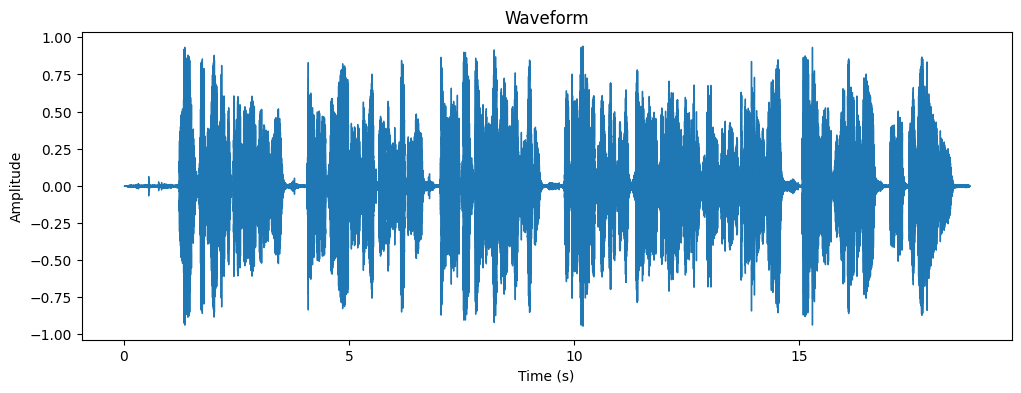

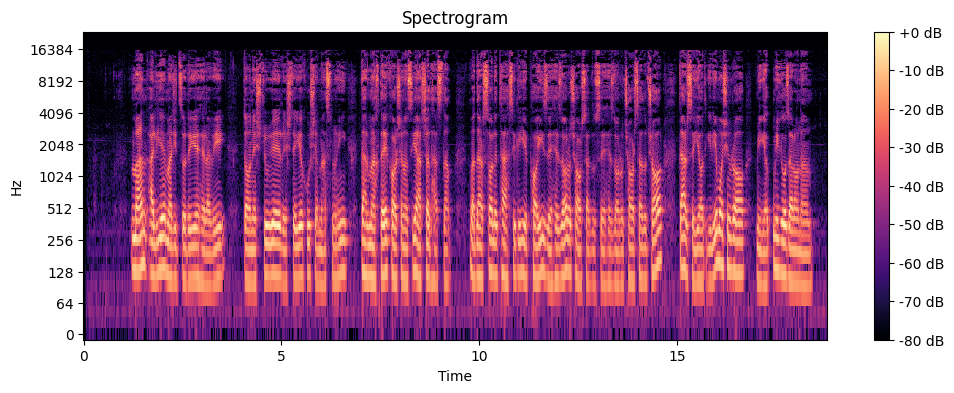

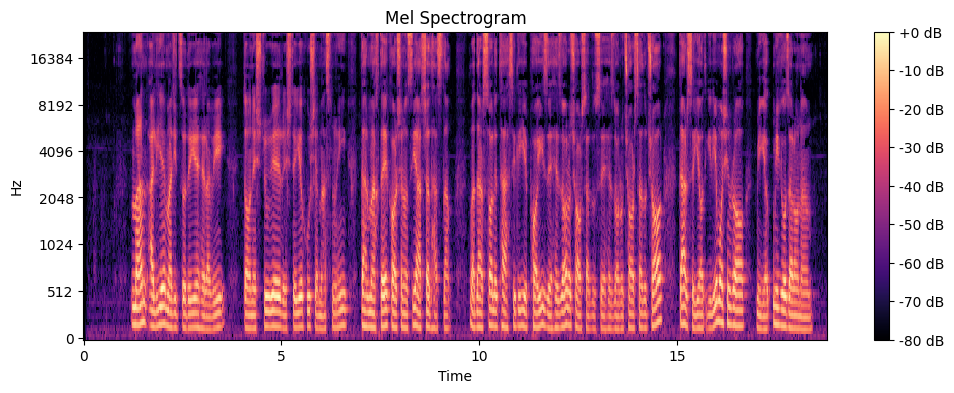

In [ ]:
audio_path = metadata['path'][0]

y, sr = librosa.load(audio_path, sr=None)

# **1. Waveform**
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

# **2. Spectrogram**
D = np.abs(librosa.stft(y)) 
plt.figure(figsize=(12, 4))
librosa.display.specshow(librosa.amplitude_to_db(D, ref=np.max), sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

# **3. Mel Spectrogram**
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spec_db, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()


In [6]:
print("Sample rate: ", sr)  

Sample rate:  48000


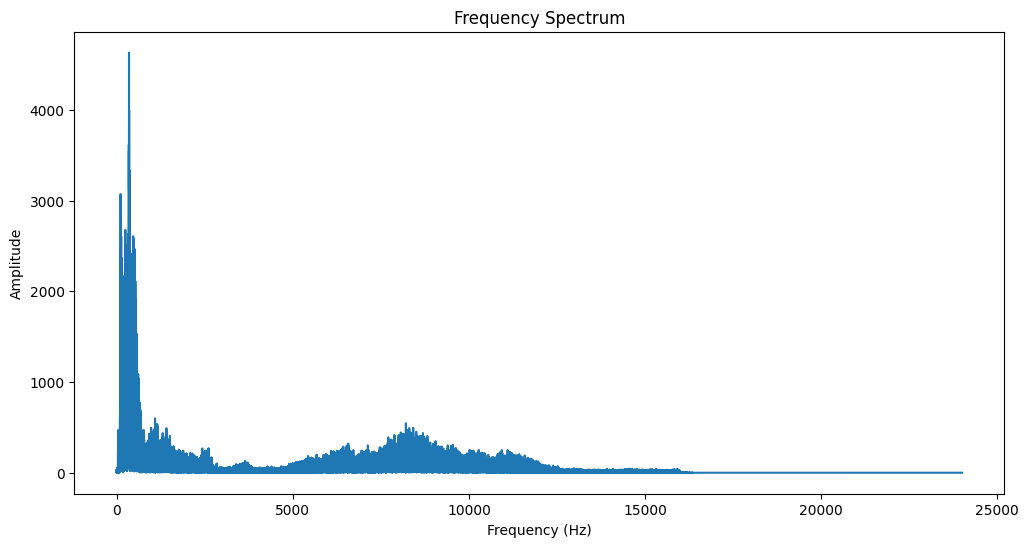

In [7]:
fft_spectrum = np.fft.fft(y)
frequencies = np.fft.fftfreq(len(fft_spectrum), 1/sr)

plt.figure(figsize=(12, 6))
plt.plot(frequencies[:len(frequencies)//2], np.abs(fft_spectrum)[:len(fft_spectrum)//2])
plt.title("Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.show()

In [8]:
female_sample = metadata[metadata['gender'] == 'female'].iloc[0]    

..\dataset\HW1_M\HW1_intro_610300070_female.mp3


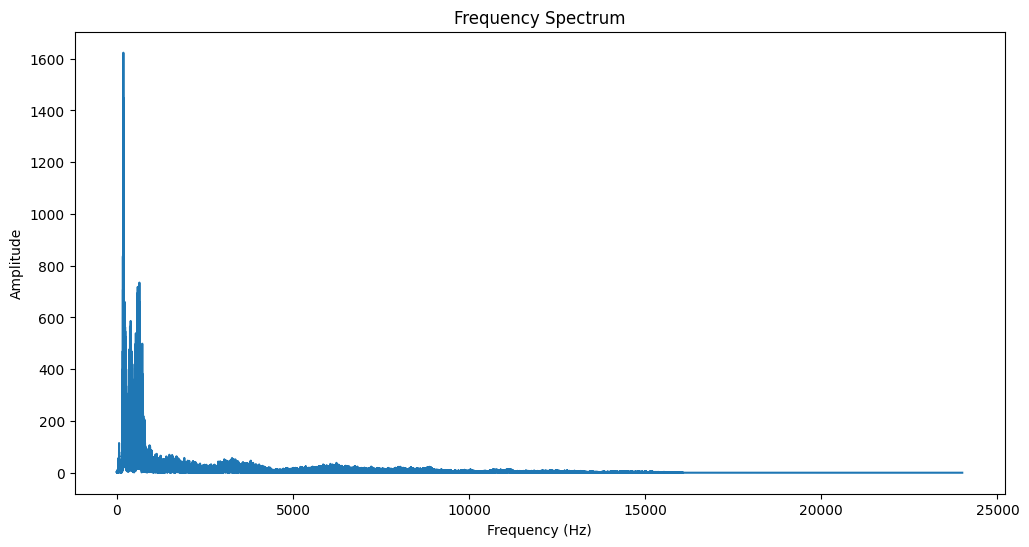

In [10]:
audio_path = female_sample['path']
print(audio_path)
y, sr = librosa.load(audio_path, sr=None)
fft_spectrum = np.fft.fft(y)
frequencies = np.fft.fftfreq(len(fft_spectrum), 1/sr)

plt.figure(figsize=(12, 6))
plt.plot(frequencies[:len(frequencies)//2], np.abs(fft_spectrum)[:len(fft_spectrum)//2])
plt.title("Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.show()

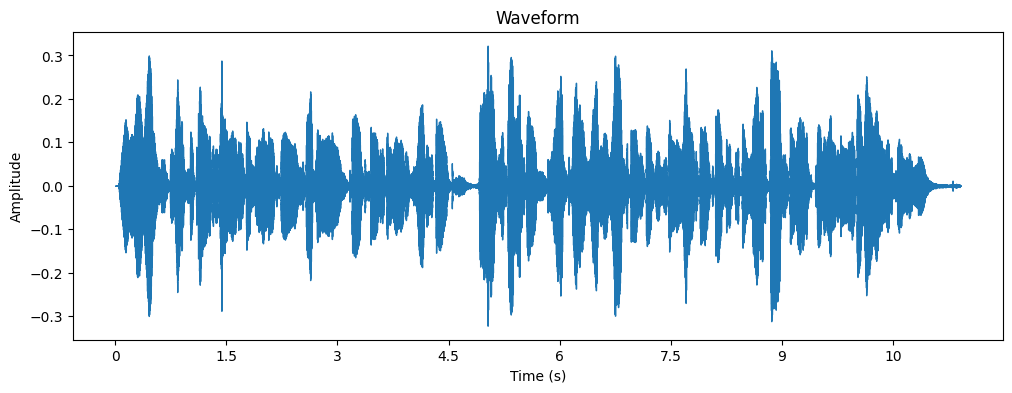

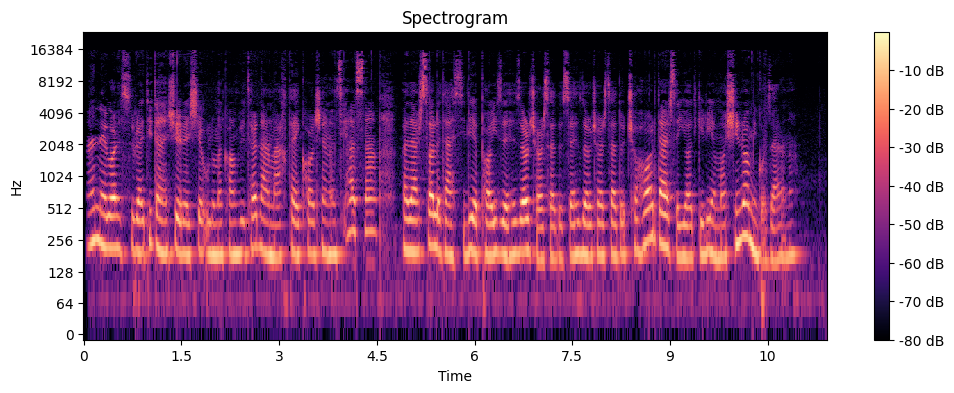

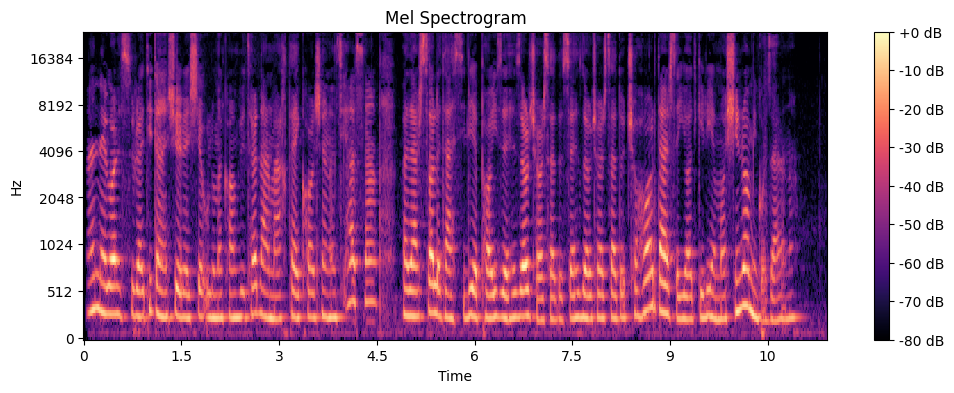

In [11]:
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

D = np.abs(librosa.stft(y))  
plt.figure(figsize=(12, 4))
librosa.display.specshow(librosa.amplitude_to_db(D, ref=np.max), sr=sr, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spec_db, sr=sr, x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()


In [12]:
print("Sample rate: ", sr)

Sample rate:  48000


In [13]:
for index, data in metadata.iterrows():
    path = data['path']
    y, sr = librosa.load(path, sr=None)
    print("index: ", index, "sample rate: ", sr)
    metadata.at[index, 'sample_rate'] = sr

index:  0 sample rate:  48000
index:  1 sample rate:  48000
index:  2 sample rate:  48000
index:  3 sample rate:  48000
index:  4 sample rate:  48000
index:  5 sample rate:  48000
index:  6 sample rate:  48000
index:  7 sample rate:  48000
index:  8 sample rate:  48000
index:  9 sample rate:  48000
index:  10 sample rate:  48000
index:  11 sample rate:  44100
index:  12 sample rate:  48000
index:  13 sample rate:  44100
index:  14 sample rate:  48000
index:  15 sample rate:  48000
index:  16 sample rate:  48000
index:  17 sample rate:  48000
index:  18 sample rate:  48000
index:  19 sample rate:  44100
index:  20 sample rate:  48000
index:  21 sample rate:  44100
index:  22 sample rate:  44100
index:  23 sample rate:  48000
index:  24 sample rate:  48000
index:  25 sample rate:  44100
index:  26 sample rate:  44100
index:  27 sample rate:  44100
index:  28 sample rate:  44100
index:  29 sample rate:  48000
index:  30 sample rate:  48000
index:  31 sample rate:  44100
index:  32 sample 

In [14]:
metadata['sample_rate'].value_counts()

sample_rate
48000.0    497
44100.0    315
16000.0      9
24000.0      1
Name: count, dtype: int64

In [28]:
print(metadata[metadata['sample_rate'] == 24000])

                      filename question_number student_id gender  \
288  HW1_Q2_810103057_male.mp3              Q2  810103057   male   

                                           path  has_intro  sample_rate  
288  ..\dataset\HW1_M\HW1_Q2_810103057_male.mp3          1      24000.0  


In [16]:
TARGET_SAMPLE_RATE = 44100  # Choose 44100 Hz as the standard rate

def resample_audio(input_path, output_path, target_sr=TARGET_SAMPLE_RATE):
    """Resamples an audio file to the target sample rate and saves it."""
    if os.path.exists(output_path):
        print(f"Already exists: {output_path}")
        return
    sr = metadata[metadata['path'] == input_path]['sample_rate'].values[0]
    if sr != target_sr:
        y, sr = librosa.load(input_path, sr=None)
        y_resampled = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
        sf.write(output_path, y_resampled, target_sr)  # Save resampled file
        print(f"Resampled: {input_path} -> {output_path}")
    else:
        shutil.copy(input_path, output_path)
        print(f"Already at target sample rate: {input_path}")

# Example usage (loop over dataset)
dataset_path = "..\dataset\HW1_M"
output_directory = "..\dataset\HW1_M_resampled"

os.makedirs(output_directory, exist_ok=True)

for filename in os.listdir(dataset_path):
    if filename.endswith(".mp3"):
        input_file = os.path.join(dataset_path, filename)
        output_file = os.path.join(output_directory, filename)
        resample_audio(input_file, output_file)


Already exists: ..\dataset\HW1_M_resampled\HW1-intro-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-intro-810801075-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-intro-Student-810101423_male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q1-1-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q1-2-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q1-3-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q1-810801075-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q2-1-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q2-2-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q2-3-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q2-810801075-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q3-810103226-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q3-810801075-male.mp3
Already exists: ..\dataset\HW1_M_resampled\HW1-Q4-1-810103226-male.mp3
Alr

In [32]:
for index, data in metadata.iterrows():
    path = data['path']
    path = path.replace("HW1_M", "HW1_M_resampled")
    y, sr = librosa.load(path, sr=None)
    print("index: ", index, "sample rate: ", sr)
    metadata.at[index, 'sample_rate_resampled'] = sr

index:  0 sample rate:  44100
index:  1 sample rate:  44100
index:  2 sample rate:  44100
index:  3 sample rate:  44100
index:  4 sample rate:  44100
index:  5 sample rate:  44100
index:  6 sample rate:  44100
index:  7 sample rate:  44100
index:  8 sample rate:  44100
index:  9 sample rate:  44100
index:  10 sample rate:  44100
index:  11 sample rate:  44100
index:  12 sample rate:  44100
index:  13 sample rate:  44100
index:  14 sample rate:  44100
index:  15 sample rate:  44100
index:  16 sample rate:  44100
index:  17 sample rate:  44100
index:  18 sample rate:  44100
index:  19 sample rate:  44100
index:  20 sample rate:  44100
index:  21 sample rate:  44100
index:  22 sample rate:  44100
index:  23 sample rate:  44100
index:  24 sample rate:  44100
index:  25 sample rate:  44100
index:  26 sample rate:  44100
index:  27 sample rate:  44100
index:  28 sample rate:  44100
index:  29 sample rate:  44100
index:  30 sample rate:  44100
index:  31 sample rate:  44100
index:  32 sample 

In [18]:
metadata['sample_rate_resampled'].value_counts()

sample_rate_resampled
44100.0    822
Name: count, dtype: int64

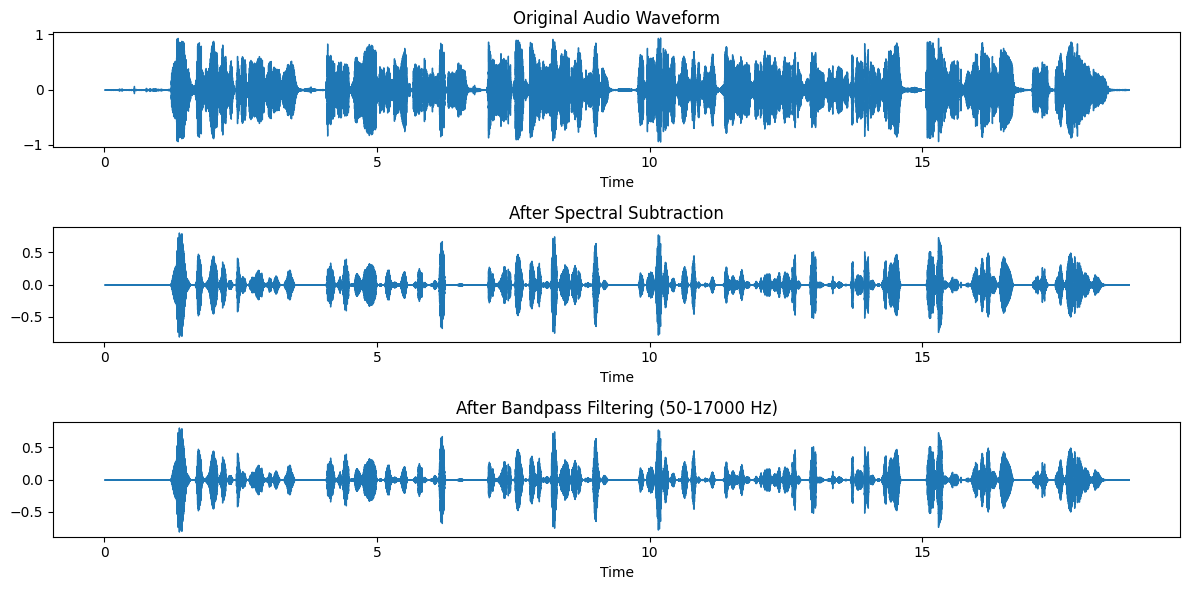

In [20]:
audio_path = metadata['path'][0]
# audio_path = female_sample['path']
y, sr = librosa.load(audio_path, sr=None)

denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)

def butter_bandpass(lowcut, highcut, sr, order=5):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype="band")
    return b, a

def apply_bandpass(y, sr, lowcut=50, highcut=17000):
    """Filters out frequencies outside human speech range."""
    b, a = butter_bandpass(lowcut, highcut, sr)
    return filtfilt(b, a, y)

final_audio = apply_bandpass(denoised_audio, sr)

plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title("Original Audio Waveform")

plt.subplot(3, 1, 2)
librosa.display.waveshow(denoised_audio, sr=sr)
plt.title("After Spectral Subtraction")

plt.subplot(3, 1, 3)
librosa.display.waveshow(final_audio, sr=sr)
plt.title("After Bandpass Filtering (50-17000 Hz)")

plt.tight_layout()
plt.show()
  
sf.write("cleaned_audio.wav", final_audio, sr)


In [21]:
def denoise_audio(audio_path, output_path, lowcut=50, highcut=17000):
    if os.path.exists(output_path):
        print(f"Skipped: {output_path} already exists")
        return 
    y, sr = librosa.load(audio_path, sr=None)
    denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)
    final_audio = apply_bandpass(denoised_audio, sr, lowcut=lowcut, highcut=highcut)
    sf.write(output_path, final_audio, sr)
    print(f"Denoised and saved: {output_path}")
    
# Example usage (loop over dataset)
output_directory = "..\dataset\HW1_M_cleaned"
input_directory = "..\dataset\HW1_M_resampled"
count = 0
for filename in os.listdir(input_directory):
    if filename.endswith(".mp3"):
        print(count)
        input_file = os.path.join(input_directory, filename)
        output_file = os.path.join(output_directory, filename)
        denoise_audio(input_file, output_file)
        count += 1

0
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-810103226-male.mp3 already exists
1
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-810801075-male.mp3 already exists
2
Skipped: ..\dataset\HW1_M_cleaned\HW1-intro-Student-810101423_male.mp3 already exists
3
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-1-810103226-male.mp3 already exists
4
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-2-810103226-male.mp3 already exists
5
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-3-810103226-male.mp3 already exists
6
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q1-810801075-male.mp3 already exists
7
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-1-810103226-male.mp3 already exists
8
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-2-810103226-male.mp3 already exists
9
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-3-810103226-male.mp3 already exists
10
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q2-810801075-male.mp3 already exists
11
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q3-810103226-male.mp3 already exists
12
Skipped: ..\dataset\HW1_M_cleaned\HW1-Q3-8

In [22]:
INPUT_DIRECTORY = "../dataset/HW1_M_resampled"
OUTPUT_DIRECTORY = "../dataset/HW1_M_cleaned"

os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

def apply_bandpass(y, sr, lowcut=50, highcut=17000):
    nyquist = 0.5 * sr
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(4, [low, high], btype="band")
    return filtfilt(b, a, y)

def denoise_audio(file_name):
    input_path = os.path.join(INPUT_DIRECTORY, file_name)
    output_path = os.path.join(OUTPUT_DIRECTORY, file_name)

    if os.path.exists(output_path):
        return f"Skipped: {file_name}"

    try:
        y, sr = librosa.load(input_path, sr=None)
        denoised_audio = nr.reduce_noise(y=y, sr=sr, stationary=False)
        final_audio = apply_bandpass(denoised_audio, sr)
        sf.write(output_path, final_audio, sr)
        return f"Processed: {file_name}"

    except Exception as e:
        return f"Error processing {file_name}: {e}"

def process_all_audio():
    audio_files = [f for f in os.listdir(INPUT_DIRECTORY) if f.endswith(".mp3")]

    # Use ThreadPoolExecutor for I/O-bound tasks
    with ThreadPoolExecutor(max_workers=8) as executor: 
        future_to_file = {executor.submit(denoise_audio, file): file for file in audio_files}

        # Track progress with tqdm
        for future in tqdm(as_completed(future_to_file), total=len(audio_files)):
            print(future.result())

process_all_audio()


100%|██████████| 822/822 [00:00<00:00, 9627.03it/s]

Skipped: HW1_intro_810103172_MALE.mp3
Skipped: HW1_intro_810103169_male.mp3
Skipped: HW1_intro_810100222_female.mp3
Skipped: HW1-Q4-4-810103226-male.mp3
Skipped: HW1_intro_610300017_male.mp3
Skipped: HW1_intro_810103162_male.mp3
Skipped: HW1_intro_810100269_male.mp3
Skipped: HW1_intro_810100268_female.mp3
Skipped: HW1_intro_810103158_male.mp3
Skipped: HW1.Q1j.810102087_female.mp3
Skipped: HW1_intro_810103146_male.mp3
Skipped: HW1_intro_810103145_male.mp3
Skipped: HW1-intro-810801075-male.mp3
Skipped: HW1_intor_810103241_male.mp3
Skipped: HW1_intro_810899073_male.mp3
Skipped: HW1_intro_159403005_male.mp3
Skipped: HW1_intro_810103140_male.mp3
Skipped: HW1_intro_810801072_Male.mp3
Skipped: HW1_intro_151501033_male.mp3
Skipped: HW1_intro_810103136_male.mp3
Skipped: HW1.Q1.810102087_female.mp3
Skipped: HW1_intro_810800024_female.mp3
Skipped: HW1_intro_810100091_male.mp3
Skipped: HW1_intro_810103123_female.mp3
Skipped: HW1_intro_810100198_male.mp3
Skipped: HW1.Q2b.810102087_female.mp3
Skippe

### Frame Segmentation (Windowing)

In [40]:
SAMPLE_RATE = 44100  # Standard sample rate
WINDOW_SIZE = int(SAMPLE_RATE * 0.1)  # 100 ms window
HOP_LENGTH = WINDOW_SIZE // 2  # 50% overlap

file_path = metadata['path'][0] 
y, sr = librosa.load(file_path, sr=None)
y = y / np.max(np.abs(y))
frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH)
frames = frames.T  # Transpose to have shape (n_frames, frame_length)
file_name = "test.npy"
np.save(file_name, frames)

In [36]:
frames = np.load("test.npy")  
print(frames.shape)

(408, 4410)


In [42]:
frames = np.load("test.npy")    # Shape: (num_frames, window_size)
ENERGY_THRESHOLD = 100 
NUM_SELECTED_WINDOWS = 10  # Keep only 10 important frames per file
frame_energy = np.array([np.sum(frame**2) for frame in frames])
voiced_frames = frames[frame_energy > ENERGY_THRESHOLD]
print(voiced_frames.shape)
if len(voiced_frames) > NUM_SELECTED_WINDOWS:
    indices = np.linspace(0, len(voiced_frames) - 1, NUM_SELECTED_WINDOWS, dtype=int)
    voiced_frames = voiced_frames[indices]
np.save("test.npy", voiced_frames)
print("Selected frames shape:", voiced_frames.shape)

(9, 4410)
Selected frames shape: (9, 4410)


In [61]:
INPUT_DIRECTORY = "../dataset/HW1_M_cleaned"
OUTPUT_DIRECTORY = "../dataset/HW1_M_windows"
SAMPLE_RATE = 44100  
WINDOW_SIZE = int(SAMPLE_RATE * 0.1)  # 100 ms window
HOP_LENGTH = WINDOW_SIZE // 2  # 50% overlap
ENERGY_THRESHOLD = 100 
NUM_SELECTED_WINDOWS = 10

os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

ENERGY_THRESHOLD = 100  
NUM_SELECTED_WINDOWS = 10 

def framing_and_normalizing(file_name):
    input_path = os.path.join(INPUT_DIRECTORY, file_name)
    output_path = os.path.join(OUTPUT_DIRECTORY, file_name.replace(".mp3", ".npy"))

    if os.path.exists(output_path):
        frames = np.load(output_path)
        if frames.shape[0] >= NUM_SELECTED_WINDOWS:
            return f"Skipped: {file_name}"

    try:
        y, sr = librosa.load(input_path, sr=None)
        y = y / np.max(np.abs(y))
        
        frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH)
        frames = frames.T  # Transpose to have shape (n_frames, frame_lenght)
        
        frame_energy = np.array([np.sum(frame**2) for frame in frames]) # Compute energy for each frame
        voiced_frames = frames[frame_energy > ENERGY_THRESHOLD] # Select frames where energy is above a threshold (i.e., contains speech)
        energy = ENERGY_THRESHOLD
        while(len(voiced_frames) < 10):
            energy -= 10
            voiced_frames = frames[frame_energy > energy]
            if energy < 0:
                raise Exception("No voiced frames found")
        # If too many frames remain, select NUM_SELECTED_WINDOWS evenly
        if len(voiced_frames) > NUM_SELECTED_WINDOWS:
            indices = np.linspace(0, len(voiced_frames) - 1, NUM_SELECTED_WINDOWS, dtype=int)
            voiced_frames = voiced_frames[indices]
        np.save(output_path, voiced_frames)

        return f"Processed: {file_name} ({len(voiced_frames)} frames kept)"

    except Exception as e:
        return f"Error processing {file_name}: {e}"

def process_all_files():
    audio_files = [f for f in os.listdir(INPUT_DIRECTORY) if f.endswith(".mp3")]

    for file in tqdm(audio_files):
        print(framing_and_normalizing(file))

if __name__ == "__main__":
    process_all_files()


  1%|          | 8/822 [00:00<00:10, 77.30it/s]

Skipped: HW1-intro-810103226-male.mp3
Skipped: HW1-intro-810801075-male.mp3
Skipped: HW1-intro-Student-810101423_male.mp3
Skipped: HW1-Q1-1-810103226-male.mp3
Skipped: HW1-Q1-2-810103226-male.mp3
Skipped: HW1-Q1-3-810103226-male.mp3
Skipped: HW1-Q1-810801075-male.mp3
Skipped: HW1-Q2-1-810103226-male.mp3
Skipped: HW1-Q2-2-810103226-male.mp3
Skipped: HW1-Q2-3-810103226-male.mp3
Skipped: HW1-Q2-810801075-male.mp3
Skipped: HW1-Q3-810103226-male.mp3
Skipped: HW1-Q3-810801075-male.mp3
Skipped: HW1-Q4-1-810103226-male.mp3
Skipped: HW1-Q4-2-810103226-male.mp3
Skipped: HW1-Q4-3-810103226-male.mp3
Skipped: HW1-Q4-4-810103226-male.mp3
Skipped: HW1-Q4-810801075-male.mp3
Skipped: HW1-Q5-810801075-male.mp3


  4%|▎         | 30/822 [00:00<00:08, 89.63it/s]

Skipped: HW1-Q6-810801075-male.mp3
Skipped: HW1.Q1.810102087_female.mp3
Skipped: HW1.Q1b.810102087_female.mp3
Skipped: HW1.Q1j.810102087_female.mp3
Skipped: HW1.Q2b.810102087_female.mp3
Skipped: HW1.Q4a.810102087_female.mp3
Skipped: HW1.Q4c.810102087_female.mp3
Skipped: HW1.Q4ch.810102087_female.mp3
Skipped: HW1.Q4j.810102087_female.mp3
Skipped: HW1_intor_810103241_male.mp3
Skipped: HW1_into_810103317_male.mp3
Skipped: HW1_into_810103322_male.mp3
Skipped: HW1_intro_151501033_male.mp3
Skipped: HW1_intro_159403005_male.mp3
Skipped: HW1_intro_610300017_male.mp3
Skipped: HW1_intro_610300032_male.mp3


  6%|▌         | 50/822 [00:00<00:08, 91.58it/s]

...

Skipped: HW1_Q6_810103008_male.mp3
Skipped: HW1_Q6_810103019_male.mp3
Skipped: HW1_Q6_810103022_male.mp3
Skipped: HW1_Q6_810103054_male.mp3
Skipped: HW1_Q6_810103057_male.mp3
Skipped: HW1_Q6_810103092_male.mp3
Skipped: HW1_Q6_810103093_female.mp3
Skipped: HW1_Q6_810103106_male.mp3
Skipped: HW1_Q6_810103108_male.mp3
Skipped: HW1_Q6_810103112_male.mp3
Skipped: HW1_Q6_810103123_female.mp3
Skipped: HW1_Q6_810103136.mp3
Skipped: HW1_Q6_810103140_male.mp3
Skipped: HW1_Q6_810103145_male.mp3
Skipped: HW1_Q6_810103146_male.mp3
Skipped: HW1_Q6_810103158_male.mp3
Skipped: HW1_Q6_810103162_male.mp3
Skipped: HW1_Q6_810103169_male.mp3
Skipped: HW1_Q6_810103172_MALE.mp3
Skipped: HW1_Q6_810103183_male.mp3
Skipped: HW1_Q6_810103197_female.mp3
Skipped: HW1_Q6_810103222_male.mp3
Skipped: HW1_Q6_810103241_male.mp3


 97%|█████████▋| 797/822 [00:09<00:00, 99.68it/s]

Skipped: HW1_Q6_810103245.mp3
Skipped: HW1_Q6_810103263_male.mp3
Skipped: HW1_Q6_810103264_male.mp3
Skipped: HW1_Q6_810103269_male.mp3
Skipped: HW1_Q6_810103295_male.mp3
Skipped: HW1_Q6_810103306_male.mp3
Skipped: HW1_Q6_810103317_male.mp3
Skipped: HW1_Q6_810103322_male.mp3
Skipped: HW1_Q6_810103339.mp3
Skipped: HW1_Q6_810103345_male.mp3
Skipped: HW1_Q6_810198500_male.mp3
Skipped: HW1_Q6_810198554_female.mp3
Skipped: HW1_Q6_810199319.mp3
Skipped: HW1_Q6_810199328_male.mp3
Skipped: HW1_Q6_810199400_male.mp3
Skipped: HW1_Q6_810199417_male.mp3
Skipped: HW1_Q6_810199423_male.mp3
Skipped: HW1_Q6_810199428_male.mp3


100%|██████████| 822/822 [00:09<00:00, 86.70it/s]

Skipped: HW1_Q6_810199459_male.mp3
Skipped: HW1_Q6_810199489_female.mp3
Skipped: HW1_Q6_810199569_male.mp3
Skipped: HW1_Q6_810199570_female.mp3
Skipped: HW1_Q6_810202047_male.mp3
Skipped: HW1_Q6_810600065_female.mp3.mp3
Skipped: HW1_Q6_810600072_male.mp3
Skipped: HW1_Q6_810600088_female.mp3
Skipped: HW1_Q6_810600097_female.mp3
Skipped: HW1_Q6_810600125_male.mp3
Skipped: HW1_Q6_810600133_female.mp3
Skipped: HW1_Q6_810801072_Male.mp3
Skipped: HW1_Q6_810899073_male.mp3
Skipped: HW1_Q6_MohammadJavadMousavi-810102263_male.mp3
Skipped: HW1_Q6_Student-810101423.mp3
Skipped: ​HW1_Q2_810103224_male.mp3
Skipped: ​HW1_Q5_810103224_male.mp3
Skipped: ​HW1_Q6_810103224_male.mp3


HW1_Q3_810199319.mp3: No voiced frames found


This audio file is empty and we have to remove it from the dataset

In [64]:
metadata = metadata[metadata['path'] != '..\dataset\HW1_M\HW1_Q3_810199319.mp3']

In [65]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 821 entries, 0 to 821
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   filename               821 non-null    object 
 1   question_number        821 non-null    object 
 2   student_id             821 non-null    object 
 3   gender                 821 non-null    object 
 4   path                   821 non-null    object 
 5   has_intro              821 non-null    int64  
 6   sample_rate            821 non-null    float64
 7   sample_rate_resampled  821 non-null    float64
dtypes: float64(2), int64(1), object(5)
memory usage: 57.7+ KB


In [62]:
audio_files = [f for f in os.listdir(OUTPUT_DIRECTORY) if f.endswith(".npy")]
print("Number of files:", len(audio_files))
count = 0
for file in audio_files:
    frames = np.load(os.path.join(OUTPUT_DIRECTORY, file))
    if(frames.shape[0] != 10):
        count += 1
        print("Error: ", file, frames.shape)
print("Number of errors: ", count)

Number of files: 821
Number of errors:  0


# Feature Extraction

Let's go step by step through each feature extraction process from your audio data:

---

### **1. Log Mel Spectrogram**
The **log mel spectrogram** is a time-frequency representation of the audio, capturing the amplitude of frequency bands that correspond to the Mel scale. It is commonly used in speech and audio processing tasks.

To compute the log mel spectrogram, we can use `librosa`:

```python
import librosa
import numpy as np

def compute_log_mel_spectrogram(y, sr, n_mels=23, fmin=0, fmax=None):
    # Compute Mel spectrogram
    mel_spectrogram = librosa.feature.melspectrogram(y, sr=sr, n_mels=n_mels, fmin=fmin, fmax=fmax)
    # Convert to log scale
    log_mel_spectrogram = librosa.power_to_db(mel_spectrogram)
    return log_mel_spectrogram
```

---

### **2. MFCC (Mel Frequency Cepstral Coefficients)**
MFCCs represent the short-term power spectrum of sound and are widely used in speech and audio processing. They capture both the amplitude and frequency characteristics of the audio.

```python
def compute_mfcc(y, sr, n_mfcc=13):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    return mfcc
```

---

### **3. Spectral Centroid**
The **spectral centroid** gives a measure of the "center of mass" of the spectrum. It indicates where the center of the energy of the signal is in the frequency domain, and it is often related to the timbral texture.

```python
def compute_spectral_centroid(y, sr):
    spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    return spectral_centroid
```

---

### **4. Spectral Bandwidth**
Spectral bandwidth measures the width of the spectrum. It indicates how "sharp" or "wide" the spectrum is and is useful for capturing characteristics of sounds (e.g., noise vs. tone).

```python
def compute_spectral_bandwidth(y, sr):
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    return spectral_bandwidth
```

---

### **5. Spectral Contrast**
**Spectral contrast** captures the difference in amplitude between peaks and valleys in the sound spectrum. It is useful for differentiating sounds with different timbres.

```python
def compute_spectral_contrast(y, sr):
    spectral_contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    return spectral_contrast
```

---

### **6. Zero-Crossing Rate**
The **zero-crossing rate** captures the rate at which the signal changes from positive to negative (or vice versa), which can help capture fast transitions in speech.

```python
def compute_zero_crossing_rate(y):
    zero_crossing_rate = librosa.feature.zero_crossing_rate(y)
    return zero_crossing_rate
```

---

### **7. Energy**
Energy can be computed as the sum of the squared amplitudes of the signal, and it captures the signal’s loudness. Fast transitions can be detected by looking at energy over time.

```python
def compute_energy(y):
    energy = np.sum(np.square(y))
    return energy
```

---

### **Combining Time and Frequency Features**
Now, as you suggested, we can combine both time and frequency domain features to create a richer dataset. You can concatenate both the time-domain features (like energy, zero-crossing rate) and frequency-domain features (like MFCCs, spectral centroid, etc.) to create a larger feature vector for each window of audio.

```python
def extract_features(y, sr):
    # Time-domain features
    zero_crossing_rate = compute_zero_crossing_rate(y)
    energy = compute_energy(y)

    # Frequency-domain features
    log_mel_spectrogram = compute_log_mel_spectrogram(y, sr)
    mfcc = compute_mfcc(y, sr)
    spectral_centroid = compute_spectral_centroid(y, sr)
    spectral_bandwidth = compute_spectral_bandwidth(y, sr)
    spectral_contrast = compute_spectral_contrast(y, sr)

    # Combine the features
    features = np.concatenate([
        zero_crossing_rate,
        energy,
        log_mel_spectrogram,
        mfcc,
        spectral_centroid,
        spectral_bandwidth,
        spectral_contrast
    ], axis=0)

    return features
```

---

### **Feature Extraction for Each Window**
Now that we have a function to extract features for each window, we can iterate over each window and apply the feature extraction. Here's how you can use it for your audio data (after windowing):

```python
# Example usage
import librosa

y, sr = librosa.load("your_audio_file.wav", sr=44100)  # Replace with your file path

# Apply windowing to the audio
frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH).T  # Shape: (num_frames, frame_length)

# Extract features for each window
features_list = []
for frame in frames:
    features = extract_features(frame, sr)
    features_list.append(features)

# Convert to numpy array
features_matrix = np.array(features_list)  # Shape: (num_frames, num_features)

# Now `features_matrix` contains all features for each window
```

### **Final Output**
The result, `features_matrix`, will have the shape `(num_frames, num_features)`, where `num_frames` is the number of frames (windows) and `num_features` is the total number of features (from log mel spectrogram, MFCCs, etc.).

### **Summary of the Features to Extract:**
- **Log Mel Spectrogram**
- **MFCC**
- **Spectral Centroid**
- **Spectral Bandwidth**
- **Spectral Contrast**
- **Zero-Crossing Rate**
- **Energy**

Let me know if you need further clarification or help with any part of this process!

In [80]:
def compute_log_mel_spectrogram(y, sr, n_mels=23, fmin=0, fmax=None):
    # Compute Mel spectrogram
    mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels, fmin=fmin, fmax=fmax)
    # Convert to log scale
    log_mel_spectrogram = librosa.power_to_db(mel_spectrogram)
    return log_mel_spectrogram

def compute_mfcc(y, sr, n_mfcc=13):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    return mfcc

def compute_spectral_centroid(y, sr):
    spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    return spectral_centroid

def compute_spectral_bandwidth(y, sr):
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
    return spectral_bandwidth

def compute_spectral_contrast(y, sr):
    spectral_contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    return spectral_contrast

def compute_zero_crossing_rate(y):
    zero_crossing_rate = librosa.feature.zero_crossing_rate(y)
    return zero_crossing_rate

def compute_energy(y):
    energy = np.sum(np.square(y))
    return energy

def extract_features(y, sr):
    # Time-domain features
    zero_crossing_rate = compute_zero_crossing_rate(y)
    print("zero_crossing",zero_crossing_rate.shape)
    # print(zero_crossing_rate)
    energy = compute_energy(y)
    print("energy", energy.shape)

    # Frequency-domain features
    log_mel_spectrogram = compute_log_mel_spectrogram(y, sr)
    mfcc = compute_mfcc(y, sr)
    spectral_centroid = compute_spectral_centroid(y, sr)
    spectral_bandwidth = compute_spectral_bandwidth(y, sr)
    spectral_contrast = compute_spectral_contrast(y, sr)
    
    print("log mel",log_mel_spectrogram.shape)
    print("mfcc", mfcc.shape)
    print("centroid",spectral_centroid.shape)
    print("bandwidth", spectral_bandwidth.shape)
    print("contrast",spectral_contrast.shape)
    

    # Combine the features
    # features = np.concatenate([
    #     zero_crossing_rate,
    #     energy,
    #     log_mel_spectrogram,
    #     mfcc,
    #     spectral_centroid,
    #     spectral_bandwidth,
    #     spectral_contrast
    # ], axis=0)
    features = []
    return features



In [84]:
file_path = metadata['path'][0]
y, sr = librosa.load(file_path, sr=44100)  # Replace with your file path

# Apply windowing to the audio
frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH).T  # Shape: (num_frames, frame_length)

# Extract features for each window
features_list = []
# frames_9 = frames[:9]
# extract_features(frames_9, sr)
extract_features(frames[0], sr)
# for frame in frames:
#     features = extract_features(frame, sr)
#     # features_list.append(feature)

# Convert to numpy array
# features_matrix = np.array(features_list)  # Shape: (num_frames, num_features)
# print(features_matrix.shape)

# Now `features_matrix` contains all features for each window


zero_crossing (1, 9)
energy ()
log mel (23, 9)
mfcc (13, 9)
centroid (1, 9)
bandwidth (1, 9)
contrast (7, 9)


[]

In [87]:
file_path = metadata['path'][0]
y, sr = librosa.load(file_path, sr=44100)  # Replace with your file path

# Apply windowing to the audio
frames = librosa.util.frame(y, frame_length=WINDOW_SIZE, hop_length=HOP_LENGTH).T  # Shape: (num_frames, frame_length)

frame = frames[0]  # Taking the first frame

# Extract each feature individually
zero_crossing = librosa.feature.zero_crossing_rate(frame)
print(f"Zero-crossing shape: {zero_crossing.shape}")  # Should be (1, 1) for one frame

log_mel_spectrogram = librosa.feature.melspectrogram(y=frame, sr=sr)
print(f"Log Mel Spectrogram shape: {log_mel_spectrogram.shape}")  # Should be (n_mels, 1) for one frame

mfcc = librosa.feature.mfcc(y=frame, sr=sr)
print(f"MFCC shape: {mfcc.shape}")  # Should be (n_mfcc, 1) for one frame

centroid = librosa.feature.spectral_centroid(y=frame, sr=sr)
print(f"Spectral centroid shape: {centroid.shape}")  # Should be (1, 1) for one frame

bandwidth = librosa.feature.spectral_bandwidth(y=frame, sr=sr)
print(f"Spectral bandwidth shape: {bandwidth.shape}")  # Should be (1, 1) for one frame

contrast = librosa.feature.spectral_contrast(y=frame, sr=sr)
print(f"Spectral contrast shape: {contrast.shape}")  # Should be (n_band, 1) for one frame


Zero-crossing shape: (1, 9)
Log Mel Spectrogram shape: (128, 9)
MFCC shape: (20, 9)
Spectral centroid shape: (1, 9)
Spectral bandwidth shape: (1, 9)
Spectral contrast shape: (7, 9)


In [88]:
# Extract each feature individually for a single frame
zero_crossing = librosa.feature.zero_crossing_rate(frame, frame_length=len(frame), hop_length=len(frame), center=False)
print(f"Zero-crossing shape: {zero_crossing.shape}")  # Should be (1, 1) for one frame

log_mel_spectrogram = librosa.feature.melspectrogram(y=frame, sr=sr, n_fft=len(frame), hop_length=len(frame), center=False)
print(f"Log Mel Spectrogram shape: {log_mel_spectrogram.shape}")  # Should be (n_mels, 1) for one frame

mfcc = librosa.feature.mfcc(y=frame, sr=sr, n_fft=len(frame), hop_length=len(frame), center=False)
print(f"MFCC shape: {mfcc.shape}")  # Should be (n_mfcc, 1) for one frame

centroid = librosa.feature.spectral_centroid(y=frame, sr=sr, n_fft=len(frame), hop_length=len(frame), center=False)
print(f"Spectral centroid shape: {centroid.shape}")  # Should be (1, 1) for one frame

bandwidth = librosa.feature.spectral_bandwidth(y=frame, sr=sr, n_fft=len(frame), hop_length=len(frame), center=False)
print(f"Spectral bandwidth shape: {bandwidth.shape}")  # Should be (1, 1) for one frame

contrast = librosa.feature.spectral_contrast(y=frame, sr=sr, n_fft=len(frame), hop_length=len(frame), center=False)
print(f"Spectral contrast shape: {contrast.shape}")  # Should be (n_band, 1) for one frame

Zero-crossing shape: (1, 1)
Log Mel Spectrogram shape: (128, 1)
MFCC shape: (20, 1)
Spectral centroid shape: (1, 1)
Spectral bandwidth shape: (1, 1)
Spectral contrast shape: (7, 1)


### **Option 1: Extract Features for Each Frame Separately (With `center=False`)**
- **Pros:**
  - More precise feature extraction for each frame.
  - Ensures consistency across all features.
  - Can be used directly for **frame-level classification** (e.g., speech activity detection, phoneme classification).
  
- **Cons:**
  - Computationally expensive, as you call each feature extraction function for every frame.
  - Generates a large number of features, increasing model complexity.



### **Option 2: Concatenate Frames and Extract Features on the Whole Signal**
- **Pros:**
  - Faster, since you apply feature extraction once on a **longer segment** (e.g., the whole window or multiple concatenated windows).
  - Reduces the total number of features, which can prevent overfitting.
  - Works well for **utterance-level classification** (e.g., speaker identification, emotion recognition).

- **Cons:**
  - Might lose fine-grained temporal details.
  - Less useful if your task needs **frame-wise precision** (e.g., detecting voice activity within each frame).

### **Which One Should You Use?**
- If your task requires **detailed frame-wise information** (e.g., detecting speech activity in each frame or phoneme classification), go with **Option 1 (per-frame feature extraction with `center=False`)**.
- If you are working on a **high-level classification task** (e.g., speaker identification, emotion classification), then **Option 2 (concatenating frames before feature extraction) is better**, because it reduces dimensionality and speeds up computation.

Since your dataset consists of student voice recordings, you are likely performing **utterance-level classification or clustering** (e.g., gender classification, speaker clustering). **In this case, Option 2 is more efficient** because you don’t need frame-by-frame analysis.

#### **Use Option 2: Concatenate Frames First, Then Extract Features**
Instead of extracting features per frame, you can apply feature extraction to **the entire windowed signal** like this:

---
### **Key Benefits of This Approach**
✔ **Drastically reduces dimensionality** (no redundant frame-wise extraction).  
✔ **Much faster** because it applies feature extraction once per window instead of per frame.  
✔ **Maintains important spectral and statistical information** for classification.  


In [93]:
def extract_features(y, sr):
    """Extracts features from an entire waveform (concatenated frames)."""

    # Zero Crossing Rate
    zero_crossing_rate = librosa.feature.zero_crossing_rate(y).mean()

    # Energy (Root Mean Square)
    energy = librosa.feature.rms(y=y).mean()

    # Log Mel Spectrogram (23 Mel bands)
    log_mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=23)
    log_mel_spectrogram = librosa.power_to_db(log_mel_spectrogram, ref=np.max).mean(axis=1)

    # MFCCs (13 coefficients)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13).mean(axis=1)

    # Spectral Centroid
    spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=sr).mean()

    # Spectral Bandwidth
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr).mean()

    # Spectral Contrast (7 bands)
    spectral_contrast = librosa.feature.spectral_contrast(y=y, sr=sr).mean(axis=1)

    # Combine features into a dictionary with proper names
    feature_dict = {
        "zero_crossing_rate": zero_crossing_rate,
        "energy": energy,
        "spectral_centroid": spectral_centroid,
        "spectral_bandwidth": spectral_bandwidth
    }

    # Add log mel spectrogram features
    for i, val in enumerate(log_mel_spectrogram):
        feature_dict[f"log_mel_{i+1}"] = val

    # Add MFCC features
    for i, val in enumerate(mfcc):
        feature_dict[f"mfcc_{i+1}"] = val

    # Add Spectral Contrast features
    for i, val in enumerate(spectral_contrast):
        feature_dict[f"spectral_contrast_{i+1}"] = val

    return feature_dict


In [94]:
def process_audio_file(file_path):
    """Loads .npy file, concatenates frames, extracts features, and returns a dictionary."""
    
    try:
        # Load frames (Each .npy file contains multiple frames)
        frames = np.load(file_path)  # Shape: (num_windows, window_size)

        # Concatenate frames into a single waveform
        waveform = frames.flatten()  # 1D array

        # Use pre-defined sample rate (44100 Hz)
        sr = 44100  

        # Extract features
        features = extract_features(waveform, sr)

        # Extract metadata (filename)
        file_name = os.path.basename(file_path).replace(".npy", "")

        # Add filename to the dictionary
        features["file_name"] = file_name

        return features
    
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None


In [91]:
def process_all_audio(input_dir, output_csv, num_threads=4):
    npy_files = [os.path.join(input_dir, f) for f in os.listdir(input_dir) if f.endswith(".npy")]
    
    results = []
    with ThreadPoolExecutor(max_workers=num_threads) as executor:
        future_to_file = {executor.submit(process_audio_file, file): file for file in npy_files}
        
        for future in tqdm(as_completed(future_to_file), total=len(npy_files), desc="Processing Audio"):
            result = future.result()
            if result is not None:
                results.append(result)

    df = pd.DataFrame(results)

    df.to_csv(output_csv, index=False)
    print(f"Feature extraction complete. Data saved to {output_csv}")



In [95]:
input_directory = "../dataset/HW1_M_windows"
output_csv = "extracted_features.csv"

process_all_audio(input_directory, output_csv, num_threads=8)  

Processing Audio: 100%|██████████| 821/821 [00:11<00:00, 68.56it/s]


Feature extraction complete. Data saved to extracted_features.csv


In [126]:
dataset = pd.read_csv("extracted_features.csv")
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [106]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
Index: 821 entries, 0 to 821
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   filename               821 non-null    object 
 1   question_number        821 non-null    object 
 2   student_id             821 non-null    object 
 3   gender                 821 non-null    object 
 4   path                   821 non-null    object 
 5   has_intro              821 non-null    int64  
 6   sample_rate            821 non-null    float64
 7   sample_rate_resampled  821 non-null    float64
dtypes: float64(2), int64(1), object(5)
memory usage: 90.0+ KB


In [152]:
dataset['file_name'] = dataset['file_name'].apply(lambda x: f"{x}.mp3")

In [129]:
filename = dataset['file_name'][0]    
print(filename)
print(metadata[metadata['filename'].str.contains(filename)])

HW1-intro-810103226-male
                       filename question_number student_id gender  \
0  HW1-intro-810103226-male.mp3           intro  810103226   male   

                                            path  has_intro  sample_rate  \
0  ..\dataset\HW1_M\HW1-intro-810103226-male.mp3          1      48000.0   

   sample_rate_resampled  
0                44100.0  


In [153]:
# Add the necessary columns to the dataset DataFrame
dataset['gender'] = ""
dataset['question_number'] = ""
dataset['student_id'] = ""
dataset['has_intro'] = ""

for index, row in dataset.iterrows():
    file_name = row['file_name']
    metadata_index = metadata[metadata['filename'].str.contains(file_name, na=False)].index
    if not metadata_index.empty:
        dataset.at[index, 'gender'] = metadata.at[metadata_index[0], 'gender']
        dataset.at[index, 'question_number'] = metadata.at[metadata_index[0], 'question_number']
        dataset.at[index, 'student_id'] = metadata.at[metadata_index[0], 'student_id']
        dataset.at[index, 'has_intro'] = metadata.at[metadata_index[0], 'has_intro']
    

C:\Users\Mr. Hajiheideri\AppData\Local\Temp\ipykernel_20088\2040424751.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  metadata_index = metadata[metadata['filename'].str.contains(file_name, na=False)].index


In [154]:
metadata['gender'].value_counts()

gender
male      631
female    190
Name: count, dtype: int64

In [155]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [150]:
dataset.head()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7,file_name,gender,question_number,student_id,has_intro
0,0.127520,0.187660,3827.709230,3161.846436,-27.103724,-19.908580,-18.731739,-27.555784,-35.060772,-33.933132,...,19.719957,20.361113,21.579589,31.040876,43.693815,HW1-intro-810103226-male,male,intro,810103226,1
1,0.067635,0.072204,1900.732655,1853.380322,-28.865406,-27.435976,-24.668957,-31.310970,-41.190920,-45.734000,...,18.675907,18.265441,23.697269,35.391072,32.358513,HW1-intro-Student-810101423_male,male,intro,810101423,1
2,0.068202,0.174761,2096.918927,1669.840695,-30.945728,-29.551079,-28.308277,-30.789394,-36.443237,-39.793770,...,14.421988,18.055988,28.717973,24.215736,36.515650,HW1-intro-810801075-male,male,intro,810801075,1
3,0.143050,0.184325,4007.880311,2866.932446,-28.667967,-21.122970,-22.334070,-30.816616,-38.122734,-38.176320,...,17.275789,20.695189,19.700783,37.010561,45.548571,HW1-Q1-2-810103226-male,male,Q1-2,810103226,1
4,0.111945,0.185216,3241.388272,2394.045626,-31.292671,-27.766798,-25.669910,-24.021078,-25.776917,-28.121340,...,18.318039,17.756269,20.720554,38.641679,37.935061,HW1-Q2-1-810103226-male,male,Q2-1,810103226,1


In [169]:
dataset['gender'].value_counts()

gender
male      631
female    190
Name: count, dtype: int64

In [168]:
data = dataset[(dataset['gender'] != 'female') & (dataset['gender'] != 'male')]
filename = data['file_name'].values[0]
print(filename)
meta = metadata[metadata['filename'] == filename]

for index, row in dataset.iterrows():
    file_name = row['file_name']
    metadata_index = metadata[metadata['filename'] == filename].index
    if file_name == filename:
        dataset.at[index, 'gender'] = metadata.at[metadata_index[0], 'gender']
        dataset.at[index, 'question_number'] = metadata.at[metadata_index[0], 'question_number']
        dataset.at[index, 'student_id'] = metadata.at[metadata_index[0], 'student_id']
        dataset.at[index, 'has_intro'] = metadata.at[metadata_index[0], 'has_intro']

HW1_Q1_810102147_male (online-audio-converter.com).mp3


In [170]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 52 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

In [171]:
dataset['has_intro'].value_counts()

has_intro
1    782
0     39
Name: count, dtype: int64

In [172]:
dataset['question_number'].value_counts()   

question_number
Q3       114
intro    113
Q4       113
Q5       112
Q2       109
Q1       109
Q6       106
Q1b        4
Q2b        4
Q1a        3
Q2a        3
Q2-1       2
Q1-2       2
Q2-2       2
Q4-3       2
Q4-2       2
Q4-1       2
Q1-1       2
Q2-b       1
Q5b        1
Q1B        1
Q1-a       1
Q1-b       1
Q1C        1
Q2-a       1
Q4c        1
Q1A        1
Q4j        1
Q4ch       1
Q2-3       1
Q4a        1
Q1j        1
Q1-3       1
Q4-4       1
Q6a        1
Name: count, dtype: int64

In [173]:
dataset.to_csv("final_dataset.csv", index=False)

# Visualization

In [ ]:
data_male = dataset[dataset['gender'] == 'male']
data_female = dataset[dataset['gender'] == 'female']

In [176]:
data_male.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_11,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7
count,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,...,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000,631.000000
mean,0.047453,0.171906,1693.914624,1845.039078,-23.136273,-19.650084,-17.078493,-21.905170,-29.370349,-33.947862,...,-12.484336,-2.071918,-2.602088,18.902179,13.777602,19.403620,19.846833,22.490211,31.346008,30.099251
std,0.042087,0.024892,983.785871,373.772212,10.291480,9.109850,9.135862,10.847875,10.915999,10.101470,...,9.772112,8.614114,9.670770,2.830583,2.018775,2.718368,2.443516,2.303720,4.540064,6.023788
min,0.006679,0.012002,676.703972,1094.504697,-64.027530,-66.282900,-66.480970,-65.884480,-65.294300,-66.617930,...,-44.516323,-32.578854,-26.873856,8.741716,7.220405,9.657150,10.596599,16.311586,15.918311,13.496614
25%,0.026566,0.165352,1185.212418,1594.365825,-29.127553,-23.921136,-19.497718,-27.823671,-35.534736,-40.301819,...,-18.985596,-7.880164,-8.970754,17.275383,12.646751,17.939635,18.284730,20.916625,28.297584,26.201647
50%,0.034067,0.174624,1406.732516,1782.482437,-21.348732,-17.864610,-14.449326,-19.973518,-28.624638,-33.056020,...,-12.785420,-2.071799,-2.631689,19.318577,13.876694,19.369199,19.931256,22.306323,31.208780,29.760563
75%,0.048921,0.184591,1796.550672,2000.161193,-15.466674,-13.198956,-11.499475,-13.640156,-21.319408,-25.913677,...,-5.989921,3.812509,3.671113,20.891052,15.022266,21.246904,21.410066,24.032273,34.340828,33.629232
max,0.337223,0.255353,8456.537918,3711.510835,-4.265939,-5.610474,-4.974742,-5.276269,-8.319742,-10.938334,...,27.399490,24.490343,29.624844,26.220016,19.103845,25.885887,29.945191,31.232893,44.890301,49.033673


In [177]:
data_female.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_11,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7
count,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,...,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000,190.000000
mean,0.079864,0.167890,2554.418417,2208.190061,-28.633017,-23.467855,-25.494667,-27.577519,-33.187632,-38.756250,...,-8.803261,-5.293284,-9.422258,13.568102,15.508038,19.570336,20.070834,23.642135,31.331641,35.254774
std,0.082103,0.031709,1836.672500,421.135935,12.597910,12.928445,12.635331,13.347007,13.397737,12.492100,...,8.109504,8.089897,6.430315,2.732443,3.146671,3.595688,3.221869,2.625837,3.416310,6.725179
min,0.012914,0.001929,902.564283,1235.124816,-69.511160,-69.631996,-70.493220,-70.769890,-71.311760,-71.659270,...,-28.456097,-27.602348,-30.792100,6.134539,5.500055,7.212382,8.723677,14.126717,21.661838,21.311526
25%,0.030397,0.160742,1433.973433,1912.846213,-35.840284,-27.530031,-28.712569,-32.755578,-39.745058,-45.813048,...,-14.142315,-10.430721,-12.636220,12.016663,14.091671,17.969674,18.607430,22.075279,28.972329,30.928645
50%,0.043844,0.173940,1786.802587,2153.168673,-26.604897,-20.055691,-21.800882,-24.031399,-30.647610,-38.038351,...,-8.814052,-6.422540,-8.881369,13.374113,15.986360,20.413235,20.604596,23.827111,31.450289,34.407818
75%,0.089835,0.183248,2836.922553,2492.433591,-19.813617,-15.021039,-16.794231,-18.458046,-24.691476,-30.740578,...,-3.615856,-0.414955,-5.502725,15.196172,17.874401,21.988466,22.170000,25.133812,33.809077,39.741400
max,0.389508,0.230411,9404.544156,3828.028079,-6.803415,-5.629376,-9.378316,-9.437477,-7.448854,-12.044383,...,11.988350,16.633108,5.644680,23.625913,22.694689,26.313290,27.246823,31.761034,39.167797,50.992761


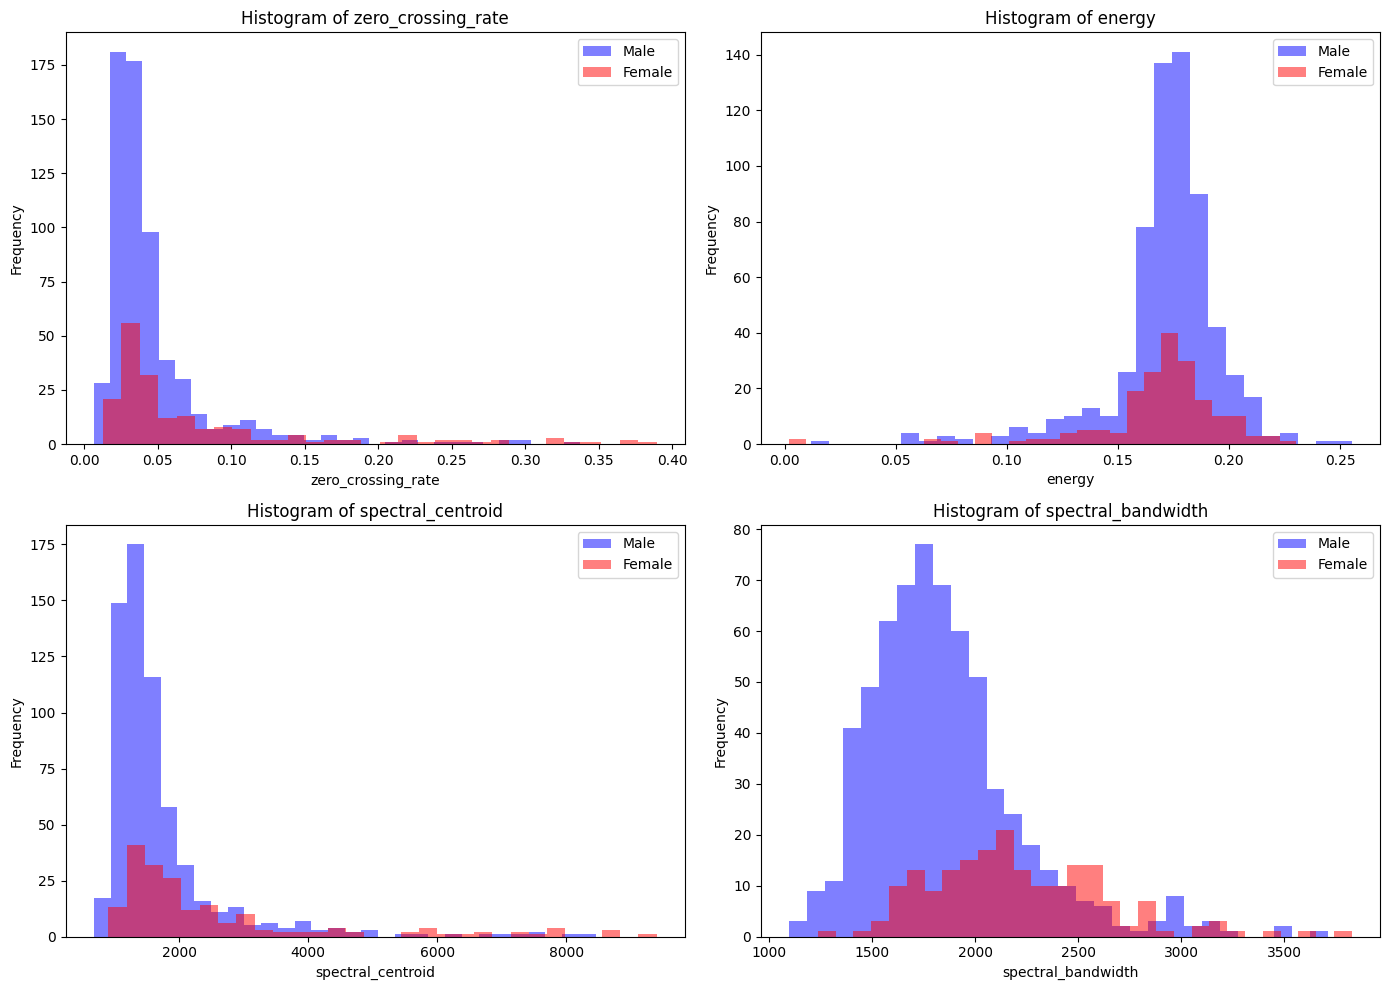

In [184]:
features_to_compare = ['zero_crossing_rate', 'energy', 'spectral_centroid', 'spectral_bandwidth']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_compare):
    axes[i].hist(data_male[feature], bins=30, alpha=0.5, label='Male', color='blue')
    axes[i].hist(data_female[feature], bins=30, alpha=0.5, label='Female', color='red')
    axes[i].set_title(f'Histogram of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')
    axes[i].legend()

plt.tight_layout()
plt.show()

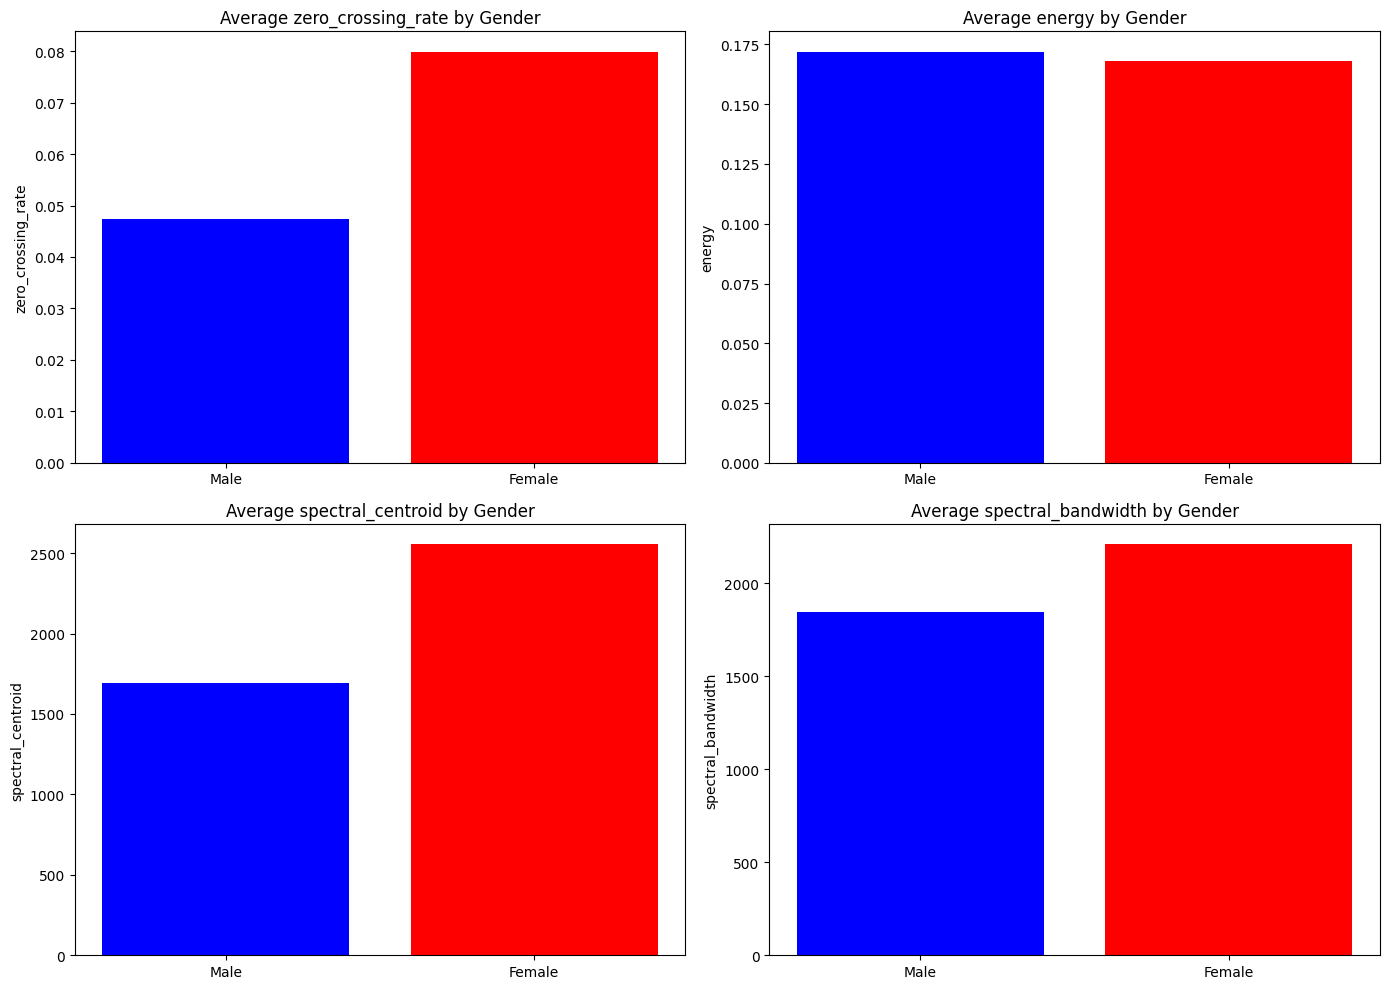

In [183]:
features_to_compare = ['zero_crossing_rate', 'energy', 'spectral_centroid', 'spectral_bandwidth']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(features_to_compare):
    male = data_male[feature].mean()
    female = data_female[feature].mean()
    axes[i].bar(['Male', 'Female'], [male, female], color=['blue', 'red'])
    axes[i].set_title(f'Average {feature} by Gender')
    axes[i].set_ylabel(feature)
    

plt.tight_layout()
plt.show()

c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\Mr. Hajiheideri\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.


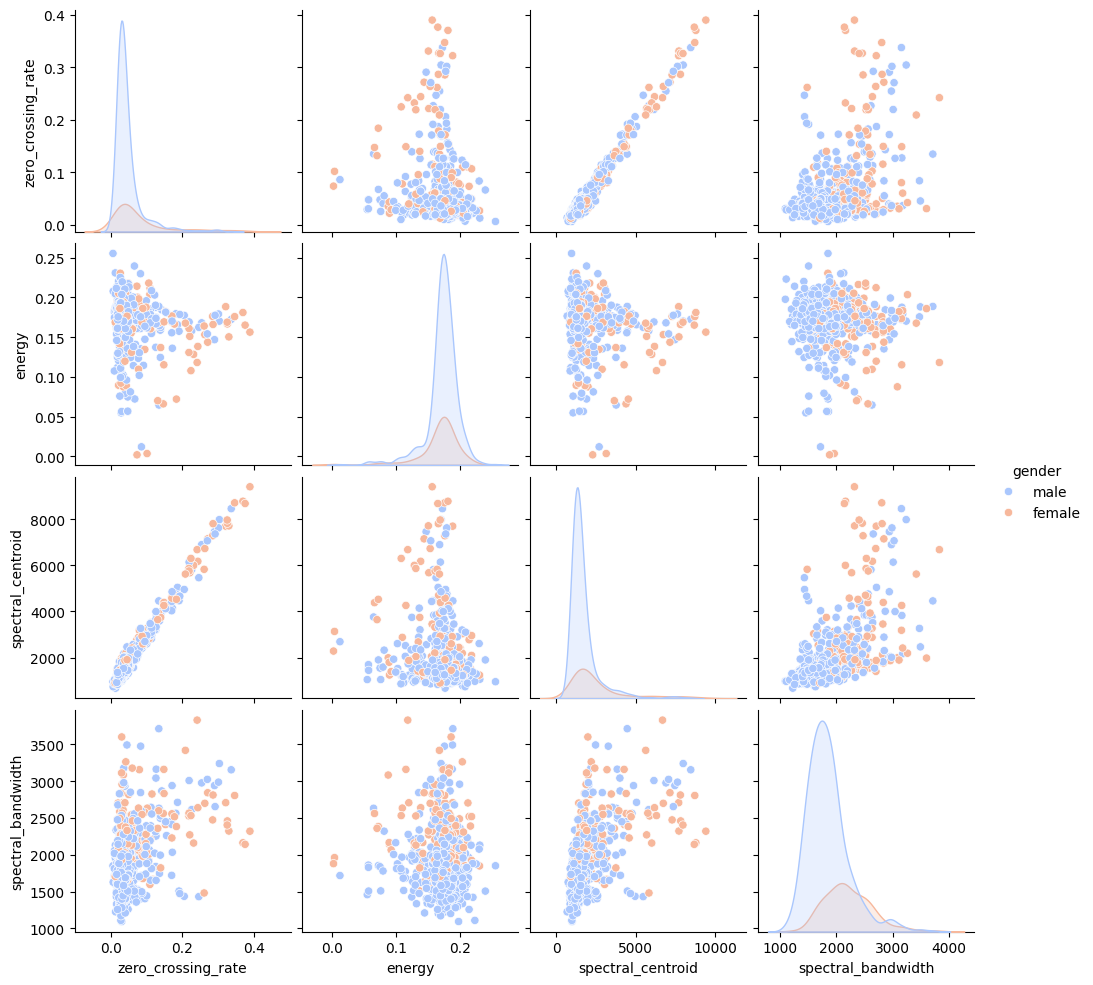

In [185]:
import seaborn as sns

features_to_compare = ['zero_crossing_rate', 'energy', 'spectral_centroid', 'spectral_bandwidth']

# Create a pairplot to visualize the relationships between the features
sns.pairplot(dataset, vars=features_to_compare, hue='gender', palette='coolwarm')
plt.show()


In [190]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 821 entries, 0 to 820
Data columns (total 55 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   zero_crossing_rate   821 non-null    float64
 1   energy               821 non-null    float64
 2   spectral_centroid    821 non-null    float64
 3   spectral_bandwidth   821 non-null    float64
 4   log_mel_1            821 non-null    float64
 5   log_mel_2            821 non-null    float64
 6   log_mel_3            821 non-null    float64
 7   log_mel_4            821 non-null    float64
 8   log_mel_5            821 non-null    float64
 9   log_mel_6            821 non-null    float64
 10  log_mel_7            821 non-null    float64
 11  log_mel_8            821 non-null    float64
 12  log_mel_9            821 non-null    float64
 13  log_mel_10           821 non-null    float64
 14  log_mel_11           821 non-null    float64
 15  log_mel_12           821 non-null    flo

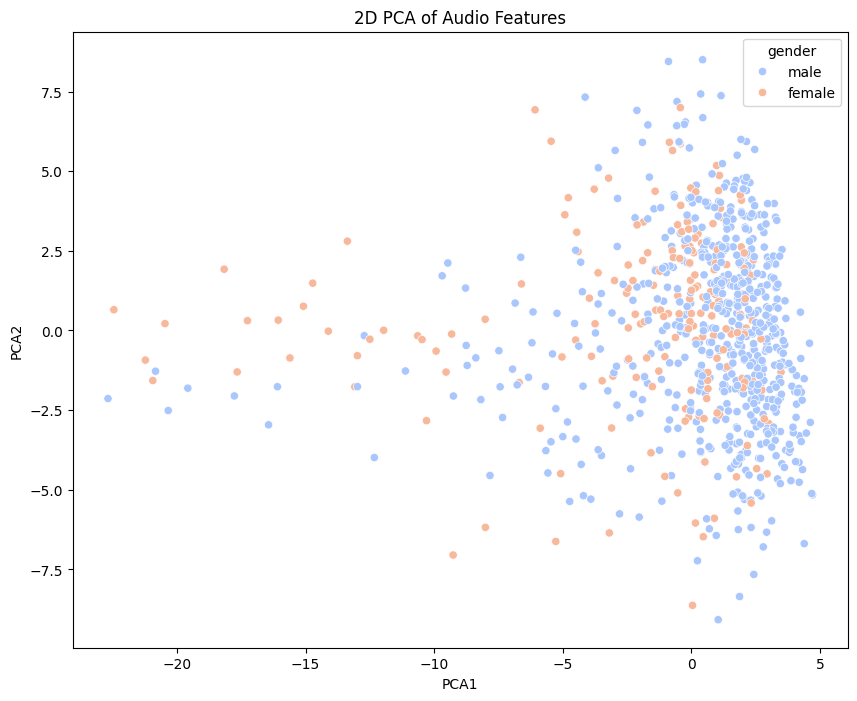

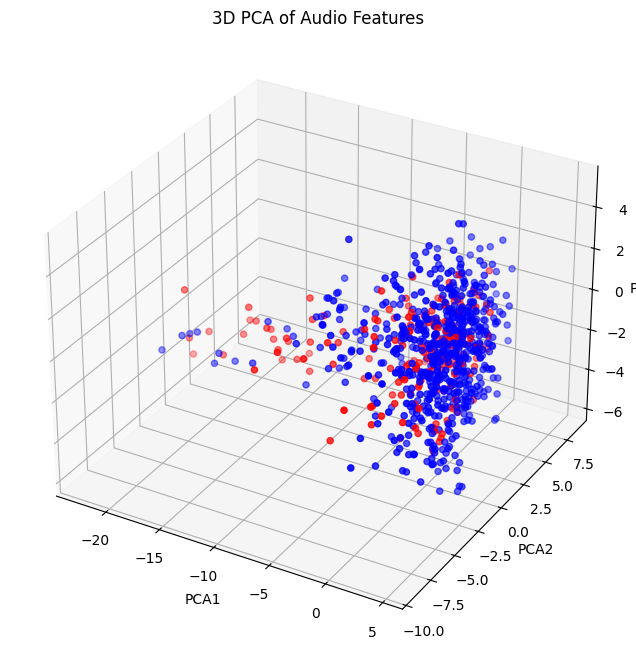

In [192]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Select only the feature columns for PCA
features = dataset.columns[:-5]  # Exclude the last 5 columns (file_name, gender, question_number, student_id, has_intro)

# Standardize the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(dataset[features])

# Apply PCA
pca = PCA(n_components=3)
pca_result = pca.fit_transform(scaled_features)

# Add PCA results to the dataset
dataset['PCA1'] = pca_result[:, 0]
dataset['PCA2'] = pca_result[:, 1]
dataset['PCA3'] = pca_result[:, 2]

# Plot 2D PCA
plt.figure(figsize=(10, 8))
sns.scatterplot(x='PCA1', y='PCA2', hue='gender', data=dataset, palette='coolwarm')
plt.title('2D PCA of Audio Features')
plt.show()

# Plot 3D PCA
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
colors = {'male': 'blue', 'female': 'red'}
ax.scatter(dataset['PCA1'], dataset['PCA2'], dataset['PCA3'], c=dataset['gender'].apply(lambda x: colors[x]))
ax.set_xlabel('PCA1')
ax.set_ylabel('PCA2')
ax.set_zlabel('PCA3')
plt.title('3D PCA of Audio Features')
plt.show()

dataset.drop(columns=['PCA1', 'PCA2', 'PCA3'], inplace=True)